# Thermal AI Lab
## Physics-Based Thermal Simulation and Anomaly Detection

This notebook analyzes the results of a physics-based thermal simulation of a data-center server rack.

The experiment combines:
1. A simplified thermal model
2. Normal server power variation
3. Two controlled fault scenarios
4. Isolation Forest anomaly detection

### Research question

Can an anomaly detector trained only on normal thermal behavior detect:
- **Cooling degradation:** a gradual loss of cooling effectiveness
- **Compute spike:** a sudden increase in server power

The purpose is not to build a production monitoring system, but to investigate how a data-driven anomaly detector behaves on physically simulated engineering data.


## 1. Experimental Setup

The thermal behavior is modeled using:

$$
C\frac{dT}{dt} = P(t) - k(T-T_{ambient})
$$

where:
- $T$ = rack temperature
- $T_{ambient}$ = cooling supply-air temperature
- $P(t)$ = server heat load
- $C$ = thermal capacitance
- $k$ = cooling effectiveness

The simulation uses a one-minute timestep.

Nominal parameters:
- $T_{ambient} = 22\,°C$
- $C = 50{,}000\,J/K$
- $k = 200\,W/K$

The corresponding thermal time constant is:

$$
\tau = \frac{C}{k} = 250\,s \approx 4.2\,min
$$

The anomaly detector is trained **only on normal baseline data**. The fault datasets are then treated as unseen evaluation scenarios.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

plt.rcParams["figure.figsize"] = (14, 6)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "results").exists() and (PROJECT_ROOT.parent / "results").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
NORMAL_PATH = RESULTS_DIR / "normal_data.csv"
COOLING_PATH = RESULTS_DIR / "scored_fault_cooling.csv"
COMPUTE_PATH = RESULTS_DIR / "scored_fault_compute.csv"

print(f"Results directory: {RESULTS_DIR.resolve()}")


Results directory: /Users/erza/thermal-ai-lab/results


## 2. Load the Experimental Data

The analysis uses:
- `normal_data.csv`
- `scored_fault_cooling.csv`
- `scored_fault_compute.csv`

The scored datasets contain the physical variables together with the Isolation Forest prediction and anomaly score.


In [2]:
normal = pd.read_csv(NORMAL_PATH)
cooling = pd.read_csv(COOLING_PATH)
compute = pd.read_csv(COMPUTE_PATH)

for df in (normal, cooling, compute):
    df["time_hours"] = df["time_seconds"] / 3600.0

print("Normal dataset:", normal.shape)
print("Cooling fault dataset:", cooling.shape)
print("Compute fault dataset:", compute.shape)
display(normal.head())


Normal dataset: (10080, 7)
Cooling fault dataset: (4320, 9)
Compute fault dataset: (4320, 9)


,time_seconds,power_w,temperature_c,k_factor,dTdt,label,time_hours
0,0.0,953.477038,27.000000,200.0,-0.000930,0,0.000000
1,60.0,1027.526710,26.944172,200.0,-0.000078,0,0.016667
2,120.0,1052.765276,26.990603,200.0,0.000933,0,0.033333
3,180.0,967.378852,27.056177,200.0,0.000108,0,0.050000
4,240.0,1003.611409,27.003549,200.0,-0.000410,0,0.066667


## 3. Baseline Behavior

Before examining faults, inspect the normal operating behavior.

The server load follows a daily cycle. The thermal model converts that changing load into rack temperature.


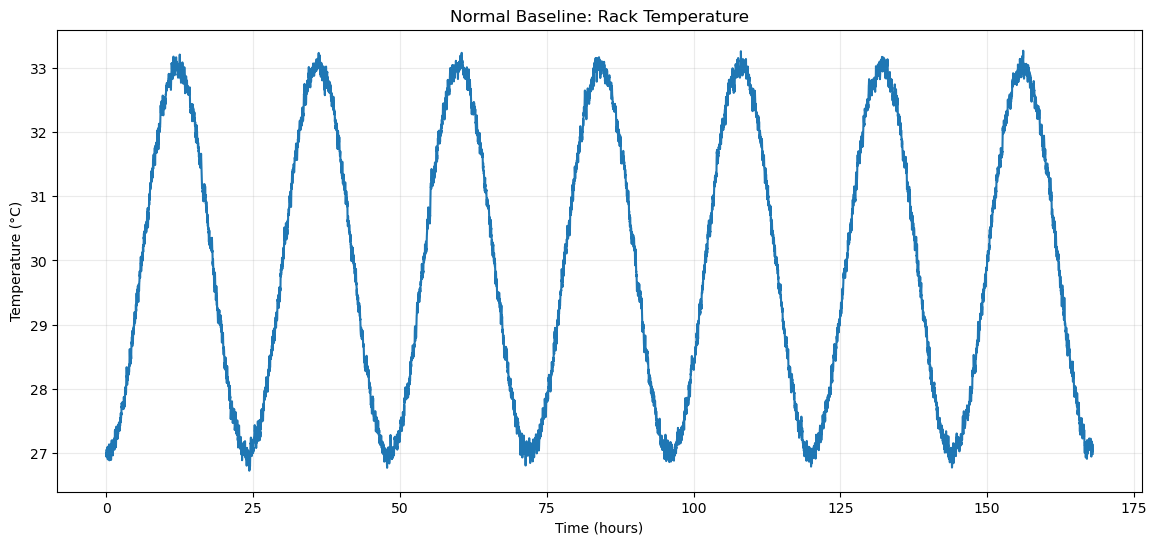

In [3]:
fig, ax = plt.subplots()
ax.plot(normal["time_hours"], normal["temperature_c"])
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Normal Baseline: Rack Temperature")
ax.grid(alpha=0.25)
plt.show()


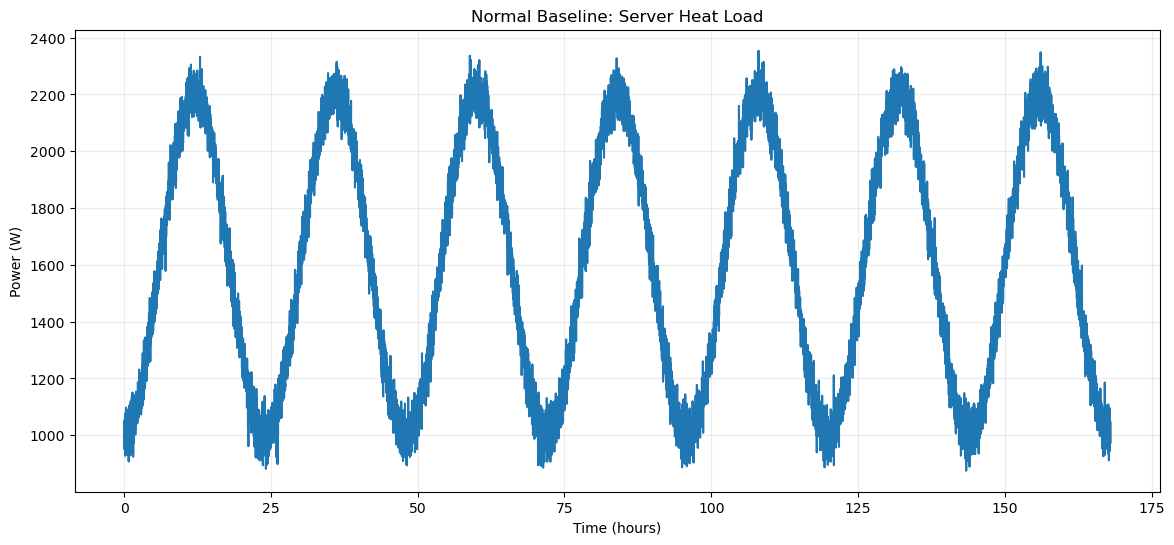

In [4]:
fig, ax = plt.subplots()
ax.plot(normal["time_hours"], normal["power_w"])
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Power (W)")
ax.set_title("Normal Baseline: Server Heat Load")
ax.grid(alpha=0.25)
plt.show()


In [5]:
print(f"Temperature range: {normal['temperature_c'].min():.2f} °C to {normal['temperature_c'].max():.2f} °C")
print(f"Power range: {normal['power_w'].min():.1f} W to {normal['power_w'].max():.1f} W")
print(f"Simulation duration: {normal['time_hours'].max():.1f} hours")


Temperature range: 26.73 °C to 33.26 °C
Power range: 875.4 W to 2353.7 W
Simulation duration: 168.0 hours


## 4. Fault 1: Cooling Degradation

The cooling fault represents a gradual reduction in cooling effectiveness.

The coefficient $k$ decreases from **200 W/K to 140 W/K over 24 hours**, after which the degraded condition is maintained.

The question is whether this slow change is sufficiently unusual for a generic Isolation Forest to detect reliably.


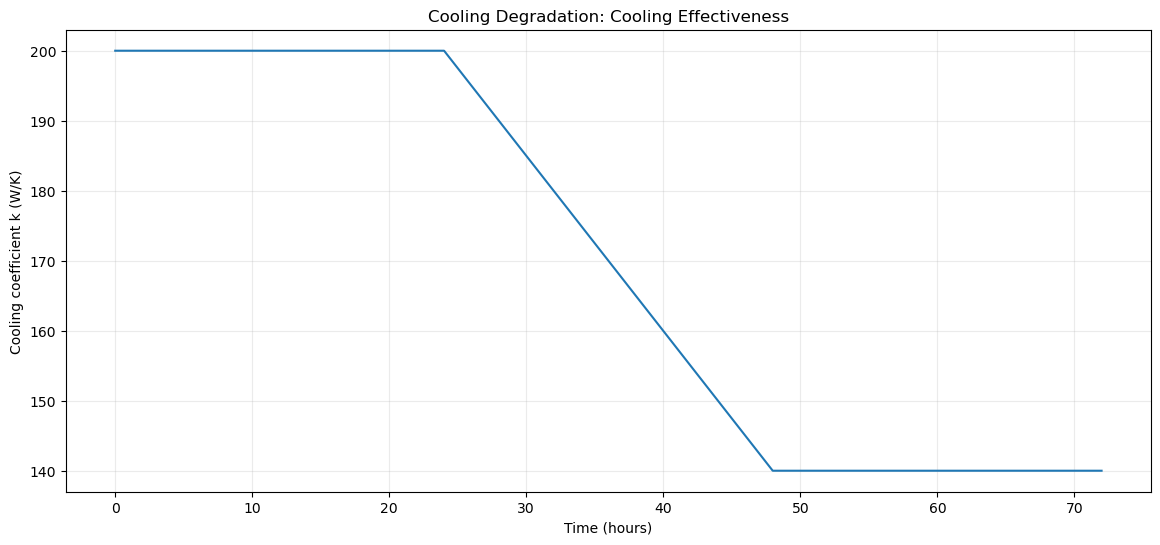

In [6]:
cooling_column = "cooling_coefficient" if "cooling_coefficient" in cooling.columns else "k_factor"

fig, ax = plt.subplots()
ax.plot(cooling["time_hours"], cooling[cooling_column])
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Cooling coefficient k (W/K)")
ax.set_title("Cooling Degradation: Cooling Effectiveness")
ax.grid(alpha=0.25)
plt.show()


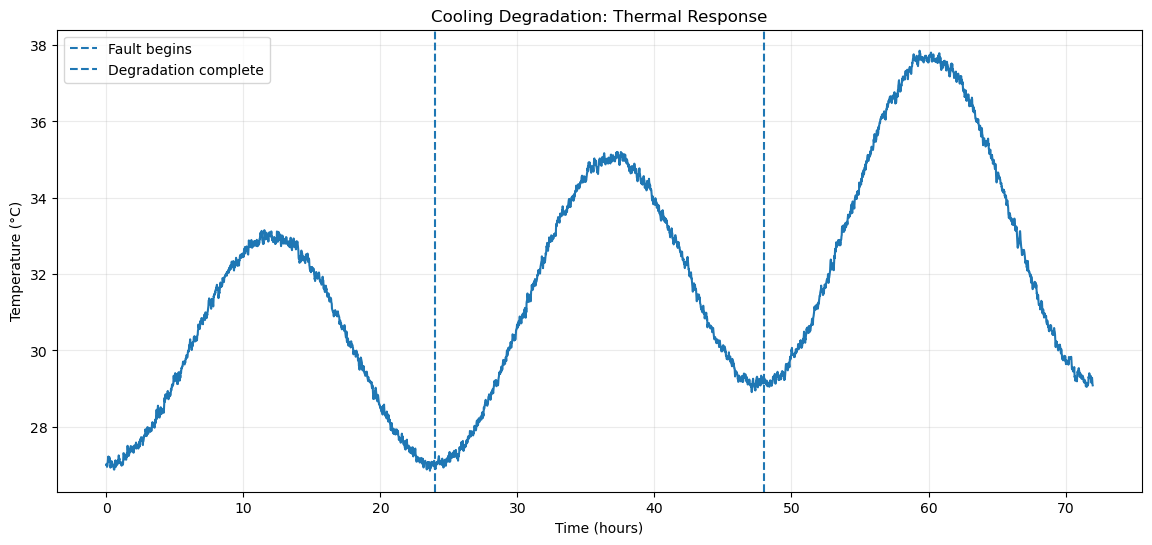

In [7]:
fig, ax = plt.subplots()
ax.plot(cooling["time_hours"], cooling["temperature_c"])
ax.axvline(24, linestyle="--", label="Fault begins")
ax.axvline(48, linestyle="--", label="Degradation complete")
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Cooling Degradation: Thermal Response")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


In [8]:
print(f"Temperature before degradation: {cooling.loc[cooling['time_hours'] < 24, 'temperature_c'].mean():.2f} °C")
print(f"Temperature after degradation: {cooling.loc[cooling['time_hours'] >= 48, 'temperature_c'].mean():.2f} °C")
print(f"Final cooling coefficient: {cooling[cooling_column].iloc[-1]:.1f} W/K")


Temperature before degradation: 30.01 °C
Temperature after degradation: 33.43 °C
Final cooling coefficient: 140.0 W/K


### Cooling Degradation: ML Result

The Isolation Forest was trained on normal data and then applied to the cooling-degradation scenario.

Because the fault develops gradually, anomalous observations can overlap substantially with the normal operating distribution. This makes gradual degradation a harder detection problem than an abrupt event.


In [9]:
cooling_report = classification_report(
    cooling["label"], cooling["ml_prediction"],
    target_names=["Normal", "Anomaly"], output_dict=True
)
display(pd.DataFrame(cooling_report).T.round(3))


,precision,recall,f1-score,support
Normal,0.341,0.996,0.508,1440.000
Anomaly,0.948,0.038,0.073,2880.000
accuracy,0.357,0.357,0.357,0.357
macro avg,0.645,0.517,0.291,4320.000
weighted avg,0.746,0.357,0.218,4320.000


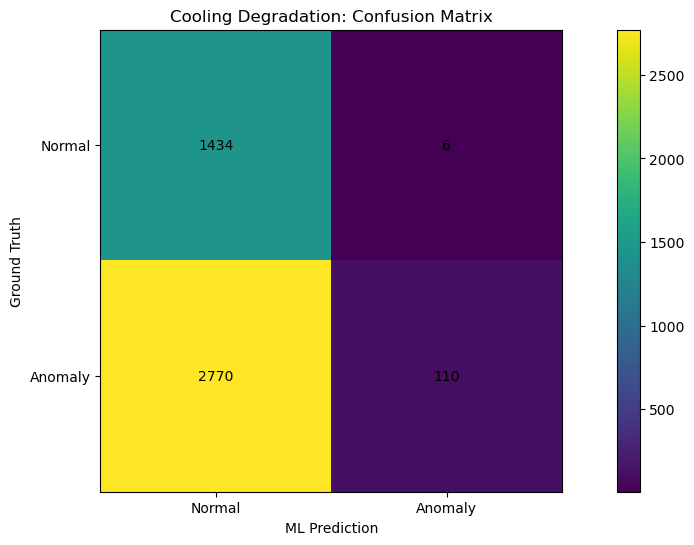

In [10]:
cm = confusion_matrix(cooling["label"], cooling["ml_prediction"])
fig, ax = plt.subplots()
im = ax.imshow(cm)
ax.set_title("Cooling Degradation: Confusion Matrix")
ax.set_xlabel("ML Prediction")
ax.set_ylabel("Ground Truth")
ax.set_xticks([0, 1], ["Normal", "Anomaly"])
ax.set_yticks([0, 1], ["Normal", "Anomaly"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.show()


## 5. Fault 2: Compute Spike

The second scenario introduces a sudden doubling of server power for **15 minutes**.

This represents a short-lived high-load event. The cooling system remains at its nominal coefficient, so the anomaly comes from the compute load rather than a mechanical cooling fault.


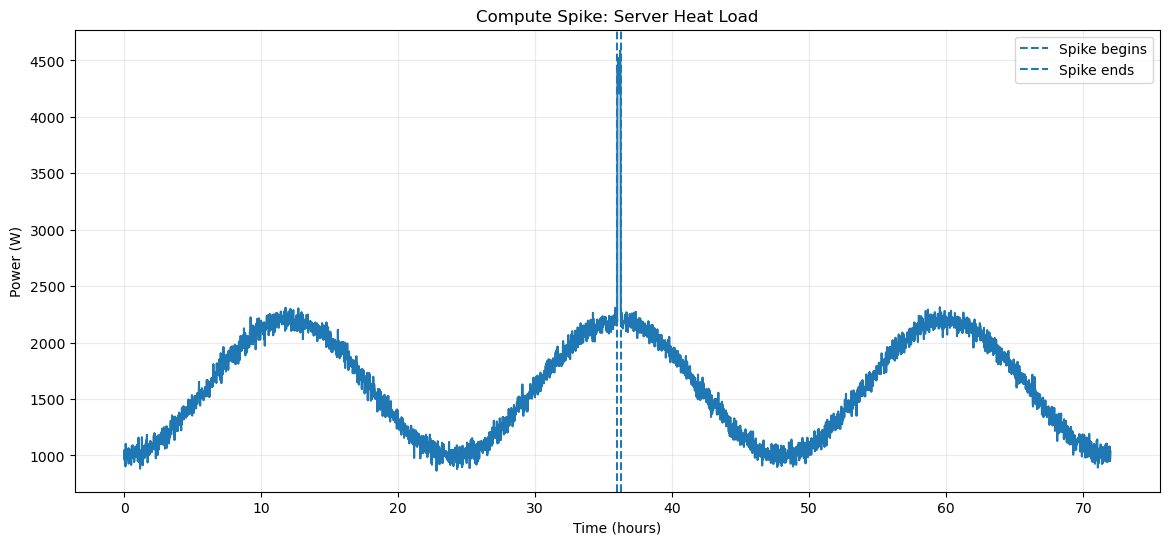

In [11]:
fig, ax = plt.subplots()
ax.plot(compute["time_hours"], compute["power_w"])
ax.axvline(36, linestyle="--", label="Spike begins")
ax.axvline(36.25, linestyle="--", label="Spike ends")
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Power (W)")
ax.set_title("Compute Spike: Server Heat Load")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


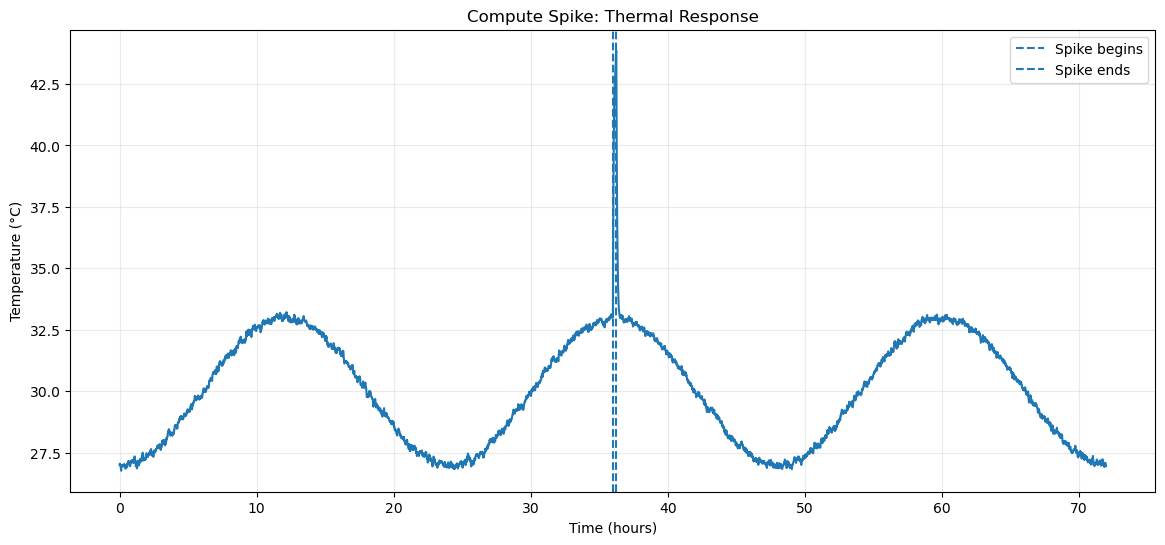

In [12]:
fig, ax = plt.subplots()
ax.plot(compute["time_hours"], compute["temperature_c"])
ax.axvline(36, linestyle="--", label="Spike begins")
ax.axvline(36.25, linestyle="--", label="Spike ends")
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Compute Spike: Thermal Response")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


### Compute Spike: ML Result

The sudden change produces a much more distinct feature pattern than the gradual cooling degradation.


In [13]:
compute_report = classification_report(
    compute["label"], compute["ml_prediction"],
    target_names=["Normal", "Anomaly"], output_dict=True
)
display(pd.DataFrame(compute_report).T.round(3))


,precision,recall,f1-score,support
Normal,1.000,0.992,0.996,4305.000
Anomaly,0.312,1.000,0.476,15.000
accuracy,0.992,0.992,0.992,0.992
macro avg,0.656,0.996,0.736,4320.000
weighted avg,0.998,0.992,0.994,4320.000


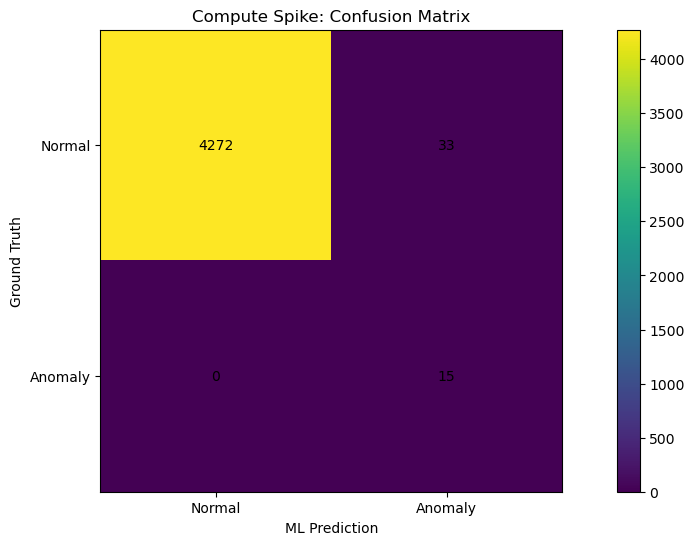

In [14]:
cm = confusion_matrix(compute["label"], compute["ml_prediction"])
fig, ax = plt.subplots()
im = ax.imshow(cm)
ax.set_title("Compute Spike: Confusion Matrix")
ax.set_xlabel("ML Prediction")
ax.set_ylabel("Ground Truth")
ax.set_xticks([0, 1], ["Normal", "Anomaly"])
ax.set_yticks([0, 1], ["Normal", "Anomaly"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.show()


## 6. Compare the Two Fault Scenarios

Accuracy alone is not sufficient because the number of normal and anomalous samples differs between the scenarios.

**Recall:** of the actual anomalous samples, how many did the detector identify?

**Precision:** of the samples flagged as anomalous, how many were actually anomalous?

These metrics are more informative than accuracy alone for this experiment.


In [15]:
comparison = pd.DataFrame({
    "Scenario": ["Cooling degradation", "Compute spike"],
    "Anomaly recall": [
        cooling_report["Anomaly"]["recall"],
        compute_report["Anomaly"]["recall"]
    ],
    "Anomaly precision": [
        cooling_report["Anomaly"]["precision"],
        compute_report["Anomaly"]["precision"]
    ],
    "Accuracy": [
        cooling_report["accuracy"],
        compute_report["accuracy"]
    ]
})
display(comparison.round(3))


,Scenario,Anomaly recall,Anomaly precision,Accuracy
0,Cooling degradation,0.038,0.948,0.357
1,Compute spike,1.000,0.312,0.992


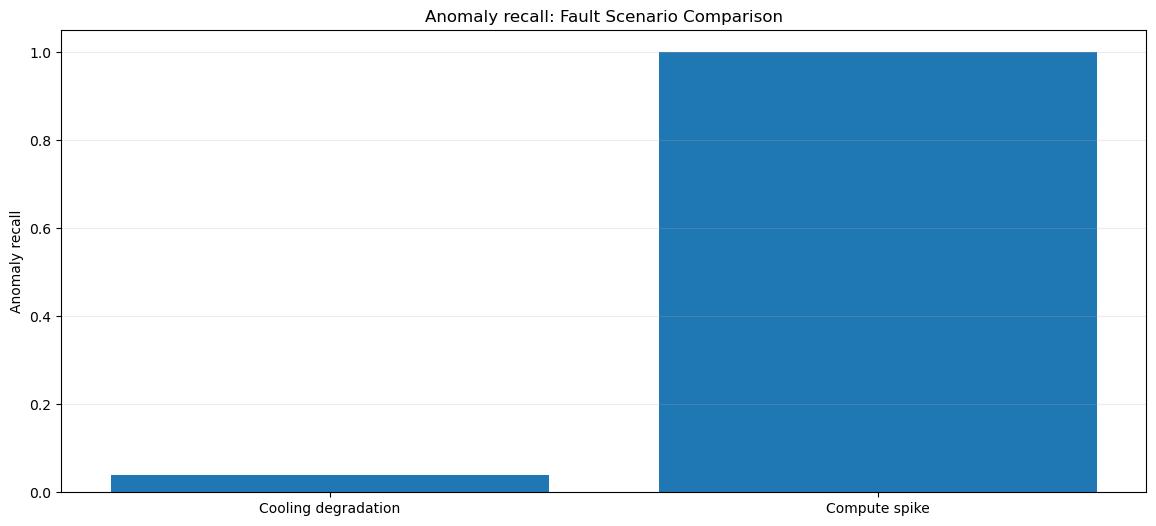

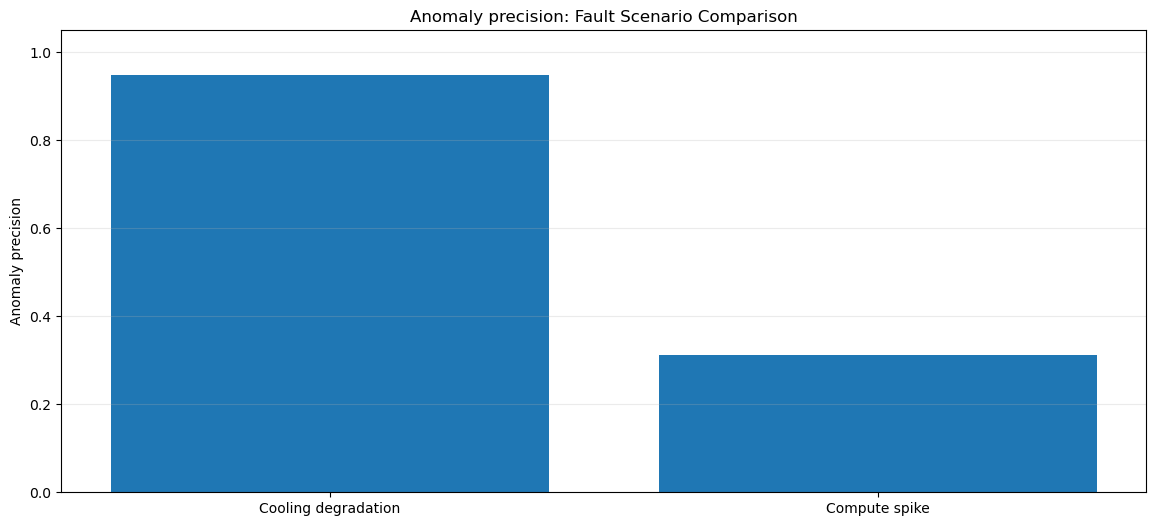

In [16]:
for metric in ["Anomaly recall", "Anomaly precision"]:
    fig, ax = plt.subplots()
    ax.bar(comparison["Scenario"], comparison[metric])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(metric)
    ax.set_title(f"{metric}: Fault Scenario Comparison")
    ax.grid(axis="y", alpha=0.25)
    plt.show()


## 7. Physical Interpretation

### Cooling degradation

As $k$ decreases, the system removes heat less effectively. The rack therefore moves toward a higher equilibrium temperature.

The gradual nature of this fault makes it difficult for a generic point-wise anomaly detector to distinguish every degraded observation from normal operating variation.

This is an important result rather than a failure of the experiment: it shows that a generic anomaly detector is not automatically a good detector of slow system degradation.

### Compute spike

During the power spike, $P(t)$ changes abruptly while the cooling coefficient remains nominal. The resulting combination of power, temperature, and temperature rate-of-change becomes more distinct from the normal operating distribution.

The detector therefore responds more strongly to the abrupt event.


## 8. Engineering Conclusions

This experiment demonstrates a workflow that connects **engineering simulation → generated data → machine learning → engineering interpretation**.

**1. Physics provides the experimental structure.**  
The thermal equation defines how server heat load and cooling effectiveness affect rack temperature. This makes the generated data interpretable rather than purely arbitrary.

**2. The detector learns normal feature distributions, not the governing physics.**  
The Isolation Forest receives `[temperature_c, power_w, dTdt]` and identifies observations that are unusual relative to the normal training distribution. It does not explicitly learn the thermal equation or understand the system's physical time constant.

**3. Abrupt faults are easier for this detector than gradual faults.**  
The compute spike creates a strong, short-lived change in the observed feature space. The cooling degradation changes the system gradually, producing substantial overlap with normal behavior.

**4. Negative results are useful engineering information.**  
The weak detection of gradual degradation identifies a limitation of the chosen method and suggests directions for further work, such as trend-based features, residual-based methods, temporal models, or alternative anomaly-detection approaches.

**5. Real-time interpretation requires a causal derivative.**  
The current simulation calculates `dTdt` with `numpy.gradient()`, which uses neighboring samples and is therefore not a strictly causal real-time feature. The present notebook should consequently be interpreted as a retrospective experiment, not a demonstration of production detection latency.


## 9. Application to Engineering Simulation

The experiment is intentionally small, but the workflow is relevant to engineering applications where simulation can be used to explore AI methods before deployment.

A production-oriented extension could replace the simplified thermal model with a more detailed calibrated system model, introduce additional operating conditions and fault modes, and compare several detection methods against measured engineering data.

The current experiment does **not** claim production predictive-maintenance performance, hardware lifetime optimization, or energy-efficiency optimization.


## 10. Limitations

- The thermal model is simplified and synthetic.
- Faults are manually injected rather than derived from measured failure data.
- Only two fault scenarios are evaluated.
- Only one anomaly-detection algorithm is tested.
- The model is not calibrated against a real data-center cooling system.
- `dTdt` currently uses a non-causal central-difference calculation.
- The experiment does not establish production detection latency or predictive-maintenance performance.
- Results depend on the selected simulation parameters and Isolation Forest configuration.


## 11. Final Takeaway

The key result is not simply that machine learning can flag anomalies.

The more useful engineering observation is that **the type of fault strongly affects detectability**.

A sudden compute event creates a distinctive change that the Isolation Forest can identify more readily. A slow cooling degradation is much harder because its observations remain closer to the normal operating distribution.

That result motivates the next engineering question:

> **Which features and detection methods are better suited to gradual physical degradation?**
